In [1]:
import numpy as np 
import pandas as pd 
import anndata as ad 
import scanpy as sc 
# import ete3
import matplotlib.pyplot as plt 
import seaborn as sns

In [20]:
scdata = sc.read_h5ad('../../sly_data/data/final_anno.h5ad')
scdata

AnnData object with n_obs × n_vars = 338818 × 3000
    obs: 'species', 'tissues', 'samples', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'cluster', 'celltype', 'coarse_celltype'
    var: 'gene_ids', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'celltype_colors', 'cluster_colors', 'coarse_celltype_colors', 'dendrogram_leiden', 'hvg', 'leiden', 'log1p', 'neighbors', 'pca', 'samples_colors', 'species_colors', 'tissues_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'harmony_0', 'umap_0'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [21]:
save_dir = 'pgls_data'
import os 

for tissue in scdata.obs.tissues.unique():
    res = {}
    for species in scdata.obs.species.unique():
        idx = (scdata.obs.tissues == tissue) & (scdata.obs.species == species)
        sub = scdata[idx].obsm['X_pca_harmony'][:, :] 
        n = len(sub)
        # # 若细胞数 ≥50 则随机抽 50 个取均值，否则全部用
        sample = sub[np.random.choice(n, size=min(n, 2000),replace=False)]
        res[species] = sample.mean(axis=0)
    df = pd.DataFrame(res).T 
    df.columns = [f'PC{i}' for i in range(1,51)]
    df.to_csv(os.path.join(save_dir, f'expr_harmony_{tissue}.csv'))

In [65]:
scdata = scdata[scdata.obs.tissues == 'HM',:]
for celltype in scdata.obs.celltype.unique():
    if celltype == 'inhibitory neuron':
        continue
    if celltype == 'excitatory neuron':
        continue
    res = {}
    for species in scdata.obs.species.unique():
        idx = (scdata.obs.celltype == celltype) & (scdata.obs.species == species)
        sub = scdata[idx].obsm['X_pca_harmony'][:, :] 
        n = len(sub)
        # # 若细胞数 ≥50 则随机抽 50 个取均值，否则全部用
        sample = sub[np.random.choice(n, size=min(n, 1000),replace=False)]
        res[species] = sample.mean(axis=0)
    df = pd.DataFrame(res).T 
    df.columns = [f'PC{i}' for i in range(1,1+df.shape[1])]
    df.to_csv(os.path.join(save_dir, f'expr_cell_{celltype}.csv'))

# celltype = 'inhibitory neuron'
# res = {}
# for species in scdata.obs.species.unique():
#     idx = (scdata.obs.celltype == celltype) & (scdata.obs.species == species)
#     subdata = scdata[idx,:]
#     idx_1 = subdata.obsm['X_umap'][:,0] <= 5 
#     idx_2 = subdata.obsm['X_umap'][:,1] <= 0
#     idx = np.logical_and(idx_1, idx_2)
#     subdata = subdata[idx,:]
    
#     sub = subdata.obsm['X_pca_harmony'][:, :10] 
    
#     # n = len(sub)
#     # # 若细胞数 ≥50 则随机抽 50 个取均值，否则全部用
#     # sample = sub[np.random.choice(n, size=min(n, 50), replace=False)]
#     res[species] = sub.mean(axis=0)
# df = pd.DataFrame(res).T 
# df.columns = [f'PC{i}' for i in range(1,1+df.shape[1])]
# df.to_csv(os.path.join(save_dir, f'expr_cell_{celltype}.csv'))


# celltype = 'excitatory neuron'
# res = {}
# for species in scdata.obs.species.unique():
#     idx = (scdata.obs.celltype == celltype) & (scdata.obs.species == species)
#     subdata = scdata[idx,:]
    
#     sub = subdata.obsm['X_pca_harmony'][:, :] 
#     sample = sub[np.random.choice(n, size=min(n, 50), replace=False)]
#     res[species] = sample.mean(axis=0)
# df = pd.DataFrame(res).T 
# df.columns = [f'PC{i}' for i in range(1,1+df.shape[1])]
# df.to_csv(os.path.join(save_dir, f'expr_cell_{celltype}.csv'))

## 抑制性优化

物种列表: ['CY', 'JT', 'QF', 'M', 'T']
  CY: 1070 cells
  JT: 731 cells
  QF: 791 cells
  M: 219 cells
  T: 285 cells

各物种细胞数: {'CY': 1070, 'JT': 731, 'QF': 791, 'M': 219, 'T': 285}

启动遗传算法: POP=20, GEN=3, WORKERS=64


Gen    0 | best=-1.086766 | mean=0.472400
Gen    2 | best=-1.247229 | mean=-0.789090

✅ 最优适应度: -1.329517
  CY: sel_idx (200,), unique=184
  JT: sel_idx (200,), unique=167
  QF: sel_idx (200,), unique=177
  M: sel_idx (200,), unique=130
  T: sel_idx (200,), unique=144

最终 df (inhibitory neuron):
          PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
CY  10.559111  9.026667  0.726195 -2.889479 -0.644545  0.694148 -1.215040   
JT   9.209751  7.776233  0.956571 -2.197816 -1.497083 -0.369947 -0.986747   
QF  10.435466  8.969052  1.185961 -2.800309 -1.150946  0.670795 -1.156766   
M    5.149426  5.434851  2.314765 -2.424692 -1.235059 -0.360716 -1.597395   
T   12.392214  9.170828  2.601285 -2.088852 -0.347803  1.794160 -0.505286   

         PC8       PC9      PC10  ...      PC41      PC42      PC43      PC44  \
CY -0.447107 -2.426283 -1.516058  ... -0.592218  1.880262 -0.417948 -1.716166   
JT -1.091945 -2.443766 -1.683072  ... -1.037097  1.683505 -0.647037 -1.411391  

/tmp/ipykernel_1582071/3030323730.py:186: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  plt.yscale('log')


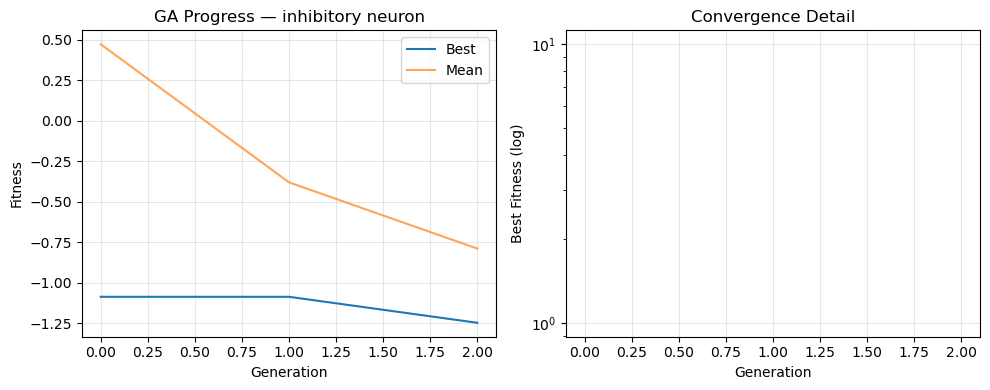

In [ ]:
# ========== 遗传算法优化 sel_idx，最小化 2*d(E,N) - d(E,E) - d(N,N) ==========
import numpy as np
import pandas as pd
import os
from multiprocessing import Pool
import matplotlib.pyplot as plt

celltype = 'inhibitory neuron'
save_dir = 'pgls_data'
os.makedirs(save_dir, exist_ok=True)

# ---------- 1. 为每个物种提取 PCA-harmony 矩阵 ----------
species_data = {}
species_order = []
for species in scdata.obs.species.unique():
    idx = (scdata.obs.celltype == celltype) & (scdata.obs.species == species)
    subdata = scdata[idx, :]
    # mask = np.logical_and(idx_1, idx_2)
    # subdata = subdata[mask, :]

    sub = subdata.obsm['X_pca_harmony'][:, :]
    species_data[species] = np.asarray(sub)
    species_order.append(species)

print("物种列表:", species_order)
for s in species_order:
    print(f"  {s}: {len(species_data[s])} cells")

# 定义回声组 E 和非回声组 N
E_GROUP = ['CY', 'JT', 'T']
N_GROUP = ['QF', 'M']

# ---------- 2. 适应度函数 ----------
def compute_fitness(sel_idx_dict):
    """计算目标函数 2*d(E,N) - d(E,E) - d(N,N)"""
    means = {}
    for sp in species_order:
        sub = species_data[sp]
        idx = sel_idx_dict[sp]
        means[sp] = sub[idx].mean(axis=0)

    def euclidean(a, b):
        return np.sqrt(np.sum((a - b) ** 2))

    # d(E,E) = 均值 (d(CY,JT), d(CY,T), d(JT,T))
    d_EE = (euclidean(means['CY'], means['JT']) +
            euclidean(means['CY'], means['T']) +
            euclidean(means['JT'], means['T'])) / 3

    # d(N,N) = d(QF, M)
    d_NN = euclidean(means['QF'], means['M'])

    # d(E,N) = 跨组平均距离
    d_EN = 0.0
    count = 0
    for e_sp in E_GROUP:
        for n_sp in N_GROUP:
            d_EN += euclidean(means[e_sp], means[n_sp])
            count += 1
    d_EN /= count

    return 2 * d_EN - d_EE - d_NN

def _eval_wrapper(ind_tuple):
    """pickle-safe wrapper for multiprocessing"""
    sel_dict = dict(zip(species_order, ind_tuple))
    return compute_fitness(sel_dict)

# ---------- 3. 遗传算法参数 ----------
N_SELECT = 1000         # 每个物种选 50 个细胞（可重复）
POP_SIZE = 20        # 种群规模
N_GEN = 3          # 迭代代数
CX_PROB = 0.8         # 交叉概率
MUT_PROB = 0.15       # 每个物种的变异概率
MUT_N_REPLACE = 8     # 每次变异替换多少个索引
ELITE_NUM = 6         # 精英保留数
TOURNEY_K = 4         # 锦标赛 k

n_cells = {sp: species_data[sp].shape[0] for sp in species_order}
print("\n各物种细胞数:", n_cells)

# ---------- 4. 遗传操作 ----------
rng = np.random.default_rng()

def create_individual():
    return tuple(rng.integers(0, n_cells[sp], size=N_SELECT) for sp in species_order)

def crossover(p1, p2):
    c1, c2 = [], []
    for i in range(len(species_order)):
        pt = rng.integers(1, N_SELECT - 1)
        c1.append(np.concatenate([p1[i][:pt], p2[i][pt:]]))
        c2.append(np.concatenate([p2[i][:pt], p1[i][pt:]]))
    return tuple(c1), tuple(c2)

def mutate(ind):
    ind_list = list(ind)
    for i in range(len(species_order)):
        if rng.random() < MUT_PROB:
            idx = rng.integers(0, N_SELECT, size=MUT_N_REPLACE)
            new_vals = rng.integers(0, n_cells[species_order[i]], size=MUT_N_REPLACE)
            arr = ind_list[i].copy()
            arr[idx] = new_vals
            ind_list[i] = arr
    return tuple(ind_list)

def tournament_select(fitness):
    idx = rng.choice(len(fitness), size=TOURNEY_K, replace=False)
    return idx[np.argmin([fitness[i] for i in idx])]

# ---------- 5. 主循环 + 6. 最终结果（都在 with 块内）----------
print(f"\n启动遗传算法: POP={POP_SIZE}, GEN={N_GEN}, WORKERS=64")

population = [create_individual() for _ in range(POP_SIZE)]
best_hist = []
mean_hist = []

with Pool(64) as pool:
    for gen in range(N_GEN):
        fitness = pool.map(_eval_wrapper, population)

        best_fit = min(fitness)
        mean_fit = np.mean(fitness)
        best_hist.append(best_fit)
        mean_hist.append(mean_fit)

        if gen % 20 == 0 or gen == N_GEN - 1:
            print(f"Gen {gen:4d} | best={best_fit:.6f} | mean={mean_fit:.6f}")

        # 精英保留
        sorted_idx = np.argsort(fitness)
        new_pop = [population[i] for i in sorted_idx[:ELITE_NUM]]

        while len(new_pop) < POP_SIZE:
            p1 = population[tournament_select(fitness)]
            p2 = population[tournament_select(fitness)]
            if rng.random() < CX_PROB:
                c1, c2 = crossover(p1, p2)
            else:
                c1, c2 = p1, p2
            new_pop.append(mutate(c1))
            if len(new_pop) < POP_SIZE:
                new_pop.append(mutate(c2))

        population = new_pop

    # ---------- 6. 最终结果（仍在 with 块内，pool 未关闭）----------
    fitness = pool.map(_eval_wrapper, population)
    best_idx_arr = np.argmin(fitness)
    best_ind = population[best_idx_arr]
    print(f"\n✅ 最优适应度: {fitness[best_idx_arr]:.6f}")

    sel_idx_dict = dict(zip(species_order, best_ind))
    for sp in species_order:
        uniq = len(np.unique(sel_idx_dict[sp]))
        print(f"  {sp}: sel_idx {sel_idx_dict[sp].shape}, unique={uniq}")

    # 构建最终 df
    res = {}
    for sp in species_order:
        res[sp] = species_data[sp][sel_idx_dict[sp]].mean(axis=0)
    df = pd.DataFrame(res).T
    df.columns = [f'PC{i}' for i in range(1, 1 + df.shape[1])]
    print(f"\n最终 df ({celltype}):")
    print(df)

    # 保存
    df.to_csv(os.path.join(save_dir, f'expr_cell_{celltype.replace(" ", "_")}_ga.csv'))
    np.savez(os.path.join(save_dir, f'sel_idx_{celltype.replace(" ", "_")}_ga.npz'),
             **{sp: sel_idx_dict[sp] for sp in species_order})
    print(f"已保存至 {save_dir}/")

# ---------- 7. 优化过程可视化 ----------
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(best_hist, label='Best', lw=1.5)
plt.plot(mean_hist, label='Mean', lw=1.5, alpha=0.7)
plt.xlabel('Generation')
plt.ylabel('Fitness')
plt.title(f'GA Progress — {celltype}')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(best_hist, lw=1.5)
plt.yscale('log')
plt.xlabel('Generation')
plt.ylabel('Best Fitness (log)')
plt.title('Convergence Detail')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(save_dir, f'ga_progress_{celltype.replace(" ", "_")}.pdf'))
plt.show()

## 兴奋性神经元优化

物种列表: ['CY', 'JT', 'QF', 'M', 'T']
  CY: 5653 cells
  JT: 6328 cells
  QF: 2154 cells
  M: 2878 cells
  T: 6458 cells

各物种细胞数: {'CY': 5653, 'JT': 6328, 'QF': 2154, 'M': 2878, 'T': 6458}

启动遗传算法: POP=64, GEN=150, WORKERS=64


Gen    0 | best=0.614239 | mean=1.736583
Gen   20 | best=-1.628757 | mean=-1.480060
Gen   40 | best=-2.593474 | mean=-2.480033
Gen   60 | best=-3.487353 | mean=-3.408511
Gen   80 | best=-4.490310 | mean=-4.387216
Gen  100 | best=-5.425049 | mean=-5.299666
Gen  120 | best=-6.429254 | mean=-6.279946
Gen  140 | best=-7.497803 | mean=-7.289928
Gen  149 | best=-7.937163 | mean=-7.823426

✅ 最优适应度: -7.989229
  CY: sel_idx (1000,), unique=911
  JT: sel_idx (1000,), unique=925
  QF: sel_idx (1000,), unique=774
  M: sel_idx (1000,), unique=821
  T: sel_idx (1000,), unique=912

最终 df (excitatory neuron):
          PC1        PC2       PC3       PC4       PC5       PC6       PC7  \
CY  15.606168  10.923428  1.780813 -1.113366 -0.058689  4.429686 -2.359560   
JT  15.548097  10.827945  1.691377 -0.327836 -1.150140  4.258269 -2.111471   
QF  11.358763   6.868573 -1.168398 -2.842236 -2.017076  0.724917 -3.303221   
M    9.843055   6.506788 -0.110979 -2.731685 -1.626766  0.850176 -3.266614   
T   14.30

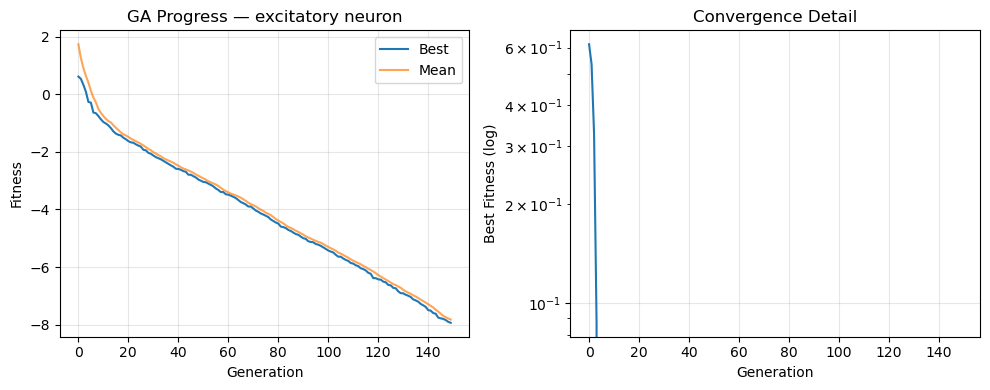

In [67]:
# ========== 遗传算法优化 sel_idx，最小化 2*d(E,N) - d(E,E) - d(N,N) ==========
import numpy as np
import pandas as pd
import os
from multiprocessing import Pool
import matplotlib.pyplot as plt

celltype = 'excitatory neuron'
save_dir = 'pgls_data'
os.makedirs(save_dir, exist_ok=True)

# ---------- 1. 为每个物种提取 PCA-harmony 矩阵 ----------
species_data = {}
species_order = []
for species in scdata.obs.species.unique():
    idx = (scdata.obs.celltype == celltype) & (scdata.obs.species == species)
    subdata = scdata[idx, :]
    # mask = np.logical_and(idx_1, idx_2)
    # subdata = subdata[mask, :]

    sub = subdata.obsm['X_pca_harmony'][:, :]
    species_data[species] = np.asarray(sub)
    species_order.append(species)

print("物种列表:", species_order)
for s in species_order:
    print(f"  {s}: {len(species_data[s])} cells")

# 定义回声组 E 和非回声组 N
E_GROUP = ['CY', 'JT', 'T']
N_GROUP = ['QF', 'M']

# ---------- 2. 适应度函数 ----------
def compute_fitness(sel_idx_dict):
    """计算目标函数 2*d(E,N) - d(E,E) - d(N,N)"""
    means = {}
    for sp in species_order:
        sub = species_data[sp]
        idx = sel_idx_dict[sp]
        means[sp] = sub[idx].mean(axis=0)

    def euclidean(a, b):
        return np.sqrt(np.sum((a - b) ** 2))

    # d(E,E) = 均值 (d(CY,JT), d(CY,T), d(JT,T))
    d_EE = (euclidean(means['CY'], means['JT']) +
            euclidean(means['CY'], means['T']) +
            euclidean(means['JT'], means['T'])) / 3

    # d(N,N) = d(QF, M)
    d_NN = euclidean(means['QF'], means['M'])

    # d(E,N) = 跨组平均距离
    d_EN = 0.0
    count = 0
    for e_sp in E_GROUP:
        for n_sp in N_GROUP:
            d_EN += euclidean(means[e_sp], means[n_sp])
            count += 1
    d_EN /= count

    return -2 * d_EN + d_EE + d_NN

def _eval_wrapper(ind_tuple):
    """pickle-safe wrapper for multiprocessing"""
    sel_dict = dict(zip(species_order, ind_tuple))
    return compute_fitness(sel_dict)

# ---------- 3. 遗传算法参数 ----------
N_SELECT = 1000         # 每个物种选 50 个细胞（可重复）
POP_SIZE = 64        # 种群规模
N_GEN = 150       # 迭代代数
CX_PROB = 0.8         # 交叉概率
MUT_PROB = 0.15       # 每个物种的变异概率
MUT_N_REPLACE = 8     # 每次变异替换多少个索引
ELITE_NUM = 6         # 精英保留数
TOURNEY_K = 4         # 锦标赛 k

n_cells = {sp: species_data[sp].shape[0] for sp in species_order}
print("\n各物种细胞数:", n_cells)

# ---------- 4. 遗传操作 ----------
rng = np.random.default_rng()

def create_individual():
    return tuple(rng.integers(0, n_cells[sp], size=N_SELECT) for sp in species_order)

def crossover(p1, p2):
    c1, c2 = [], []
    for i in range(len(species_order)):
        pt = rng.integers(1, N_SELECT - 1)
        c1.append(np.concatenate([p1[i][:pt], p2[i][pt:]]))
        c2.append(np.concatenate([p2[i][:pt], p1[i][pt:]]))
    return tuple(c1), tuple(c2)

def mutate(ind):
    ind_list = list(ind)
    for i in range(len(species_order)):
        if rng.random() < MUT_PROB:
            idx = rng.integers(0, N_SELECT, size=MUT_N_REPLACE)
            new_vals = rng.integers(0, n_cells[species_order[i]], size=MUT_N_REPLACE)
            arr = ind_list[i].copy()
            arr[idx] = new_vals
            ind_list[i] = arr
    return tuple(ind_list)

def tournament_select(fitness):
    idx = rng.choice(len(fitness), size=TOURNEY_K, replace=False)
    return idx[np.argmin([fitness[i] for i in idx])]

# ---------- 5. 主循环 + 6. 最终结果（都在 with 块内）----------
print(f"\n启动遗传算法: POP={POP_SIZE}, GEN={N_GEN}, WORKERS=64")

population = [create_individual() for _ in range(POP_SIZE)]
best_hist = []
mean_hist = []

with Pool(64) as pool:
    for gen in range(N_GEN):
        fitness = pool.map(_eval_wrapper, population)

        best_fit = min(fitness)
        mean_fit = np.mean(fitness)
        best_hist.append(best_fit)
        mean_hist.append(mean_fit)

        if gen % 20 == 0 or gen == N_GEN - 1:
            print(f"Gen {gen:4d} | best={best_fit:.6f} | mean={mean_fit:.6f}")

        # 精英保留
        sorted_idx = np.argsort(fitness)
        new_pop = [population[i] for i in sorted_idx[:ELITE_NUM]]

        while len(new_pop) < POP_SIZE:
            p1 = population[tournament_select(fitness)]
            p2 = population[tournament_select(fitness)]
            if rng.random() < CX_PROB:
                c1, c2 = crossover(p1, p2)
            else:
                c1, c2 = p1, p2
            new_pop.append(mutate(c1))
            if len(new_pop) < POP_SIZE:
                new_pop.append(mutate(c2))

        population = new_pop

    # ---------- 6. 最终结果（仍在 with 块内，pool 未关闭）----------
    fitness = pool.map(_eval_wrapper, population)
    best_idx_arr = np.argmin(fitness)
    best_ind = population[best_idx_arr]
    print(f"\n✅ 最优适应度: {fitness[best_idx_arr]:.6f}")

    sel_idx_dict = dict(zip(species_order, best_ind))
    for sp in species_order:
        uniq = len(np.unique(sel_idx_dict[sp]))
        print(f"  {sp}: sel_idx {sel_idx_dict[sp].shape}, unique={uniq}")

    # 构建最终 df
    res = {}
    for sp in species_order:
        res[sp] = species_data[sp][sel_idx_dict[sp]].mean(axis=0)
    df = pd.DataFrame(res).T
    df.columns = [f'PC{i}' for i in range(1, 1 + df.shape[1])]
    print(f"\n最终 df ({celltype}):")
    print(df)

    # 保存
    df.to_csv(os.path.join(save_dir, f'expr_cell_{celltype.replace(" ", "_")}_ga.csv'))
    np.savez(os.path.join(save_dir, f'sel_idx_{celltype.replace(" ", "_")}_ga.npz'),
             **{sp: sel_idx_dict[sp] for sp in species_order})
    print(f"已保存至 {save_dir}/")

# ---------- 7. 优化过程可视化 ----------
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(best_hist, label='Best', lw=1.5)
plt.plot(mean_hist, label='Mean', lw=1.5, alpha=0.7)
plt.xlabel('Generation')
plt.ylabel('Fitness')
plt.title(f'GA Progress — {celltype}')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(best_hist, lw=1.5)
plt.yscale('log')
plt.xlabel('Generation')
plt.ylabel('Best Fitness (log)')
plt.title('Convergence Detail')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(save_dir, f'ga_progress_{celltype.replace(" ", "_")}.pdf'))
plt.show()
df.to_csv(os.path.join(save_dir, f'expr_cell_{celltype}.csv'))